In [22]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [23]:
df = pd.read_csv("C:\\Users\\wasim\\Downloads\\Mall_Customers.csv")

In [24]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [25]:
df.shape

(200, 5)

In [26]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [28]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [29]:
df.duplicated().sum()

np.int64(0)

In [30]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [31]:
X = df.drop(['Spending Score (1-100)'], axis=1)

In [32]:
X.head()

,CustomerID,Gender,Age,Annual Income (k$)
0,1,Male,19,15
1,2,Male,21,15
2,3,Female,20,16
3,4,Female,23,16
4,5,Female,31,17


In [33]:
df['Gender'] = df['Gender'].map({
    'Male': 0,
    'Female': 1
})
X = df[['Gender', 'Age', 'Annual Income (k$)',
        'Spending Score (1-100)']]
print(X.head())
print(X.dtypes)

   Gender  Age  Annual Income (k$)  Spending Score (1-100)
0       0   19                  15                      39
1       0   21                  15                      81
2       1   20                  16                       6
3       1   23                  16                      77
4       1   31                  17                      40
Gender                    int64
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object


In [59]:
X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("X_scaled created successfully!")
print(X_scaled[:5])

X_scaled created successfully!
[[-1.42456879 -1.73899919 -0.43480148]
 [-1.28103541 -1.73899919  1.19570407]
 [-1.3528021  -1.70082976 -1.71591298]
 [-1.13750203 -1.70082976  1.04041783]
 [-0.56336851 -1.66266033 -0.39597992]]


In [60]:
inertia = []
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

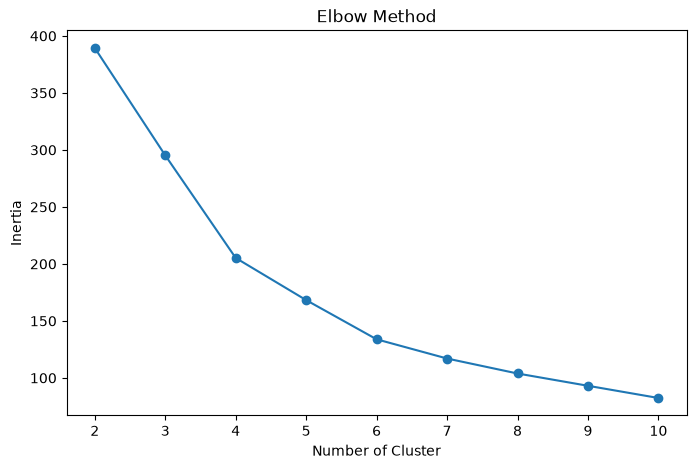

In [38]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)
plt.xlabel("Number of Cluster")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [41]:
kmeans = KMeans(
        n_clusters=4,
        random_state=42,
        n_init=10 
)
cluster = kmeans.fit_predict(X_scaled)

In [42]:
df['Cluster'] = cluster

In [43]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,0,19,15,39,2
1,2,0,21,15,81,2
2,3,1,20,16,6,2
3,4,1,23,16,77,2
4,5,1,31,17,40,2


In [44]:
df['Cluster'].value_counts().sort_index()

Cluster
0    65
1    40
2    57
3    38
Name: count, dtype: int64

In [46]:
cluster_summary = df.groupby('Cluster').mean(numeric_only=True)
cluster_summary

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,,
0,69.415385,0.569231,53.984615,47.707692,39.969231
1,161.025000,0.550000,32.875000,86.100000,81.525000
2,53.438596,0.596491,25.438596,40.000000,60.298246
3,160.552632,0.500000,39.368421,86.500000,19.578947


In [53]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [48]:
print(X_pca.shape)

(200, 2)


In [49]:
clusters = df['Cluster'].values
print(len(cluster))

200


In [54]:
pca_df = pd.DataFrame(
    X_pca,
    columns=['PCA1', 'PCA2']
)
pca_df['Cluster'] = kmeans.labels_

print(pca_df.head())
print(pca_df.columns)

       PCA1      PCA2  Cluster
0 -0.615720 -1.763481        2
1 -1.665793 -1.820747        2
2  0.337862 -1.674799        2
3 -1.456573 -1.772430        2
4 -0.038465 -1.662740        2
Index(['PCA1', 'PCA2', 'Cluster'], dtype='str')


In [57]:
print(pca_df.columns.tolist())
print(pca_df.shape)

['PCA1', 'PCA2', 'Cluster']
(200, 3)


Columns: ['PC1', 'PC2', 'Cluster']
        PC1       PC2  Cluster
0 -0.615720 -1.763481        1
1 -1.665793 -1.820747        1
2  0.337862 -1.674799        0
3 -1.456573 -1.772430        1
4 -0.038465 -1.662740        1


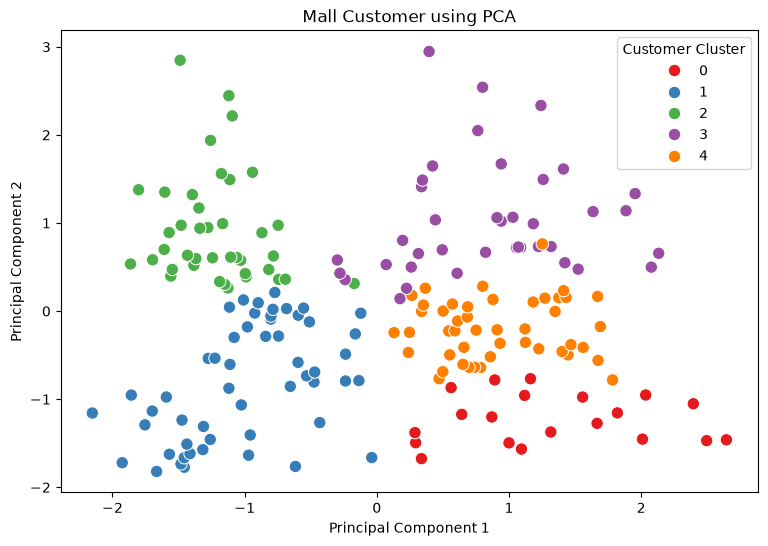

PCA explained variance: 77.57 %


In [78]:

X = X.apply(pd.to_numeric, errors='coerce')
X = X.fillna(X.median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Cluster'] = clusters

print("Columns:", pca_df.columns.tolist())
print(pca_df.head())

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Cluster',
    palette='Set1',
    s=80
)

plt.title("Mall Customer using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster")
plt.show()

print(
    "PCA explained variance:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

In [79]:
print(
    "PC1 Variance:",
    pca.explained_variance_ratio_[0]
)
print(
    "PC2 Variance:",
    pca.explained_variance_ratio_[1]
)
print(
    "Total Variance:",
    pca.explained_variance_ratio_.sum()
)

PC1 Variance: 0.4426616720824504
PC2 Variance: 0.33308378461522425
Total Variance: 0.7757454566976747


In [80]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Segment
0,1,0,19,15,39,2,VIP Premium
1,2,0,21,15,81,2,VIP Premium
2,3,1,20,16,6,2,VIP Premium
3,4,1,23,16,77,2,VIP Premium
4,5,1,31,17,40,2,VIP Premium


In [81]:
profile = df.groupby('Cluster').agg({
    'CustomerID': 'count',
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean'
}).round(2)

print(profile)

         CustomerID    Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                               
0                65  53.98               47.71                   39.97
1                40  32.88               86.10                   81.53
2                57  25.44               40.00                   60.30
3                38  39.37               86.50                   19.58


In [82]:
cluster_names = {
    0: 'Young High-Income',
    1: 'Price-Sensitive',
    2: 'VIP Premium',
    3: 'Regular Customers'
}

df['Segment'] = df['Cluster'].map(cluster_names)

print(df[['CustomerID', 'Cluster', 'Segment']].head())

   CustomerID  Cluster      Segment
0           1        2  VIP Premium
1           2        2  VIP Premium
2           3        2  VIP Premium
3           4        2  VIP Premium
4           5        2  VIP Premium


In [83]:
df[['Cluster', 'Segment']].head(20)

,Cluster,Segment
0,2,VIP Premium
1,2,VIP Premium
2,2,VIP Premium
3,2,VIP Premium
4,2,VIP Premium
5,2,VIP Premium
6,0,Young High-Income
7,2,VIP Premium
8,0,Young High-Income
9,2,VIP Premium


In [84]:
df['Segment'].value_counts()

Segment
Young High-Income    65
VIP Premium          57
Price-Sensitive      40
Regular Customers    38
Name: count, dtype: int64

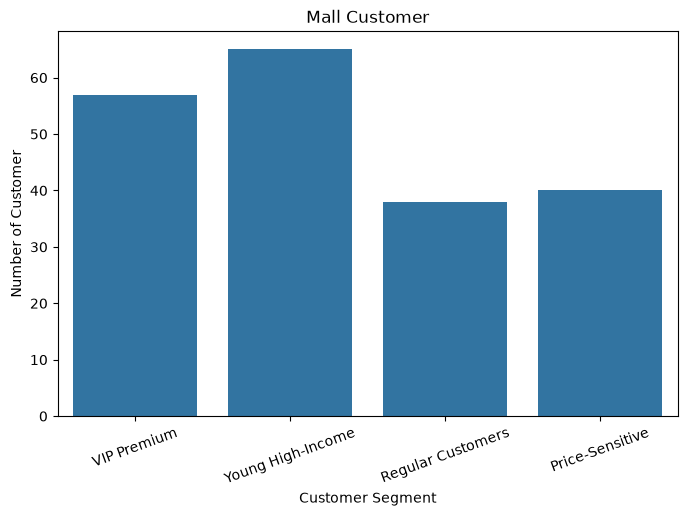

In [85]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='Segment'
)
plt.title("Mall Customer")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customer")
plt.xticks(rotation=20)
plt.show()

In [86]:
df.to_csv(
    "customer_segmentation_result.csv",
    index=False )

In [87]:
import joblib
joblib.dump(
    kmeans,
    "customer_segmentation_kmeans.pkl"
)

['customer_segmentation_kmeans.pkl']